# 02 - Exploratory Data Analysis (Phase 3)

**Project:** AI-Based Fake News Detection and News Credibility Analysis Using Machine Learning and Evidence Retrieval

**Goal:** understand the cleaned ISOT dataset thoroughly before building any ML models in Phase 4.

**Data used:** primarily `data/processed/train.csv`. The validation and test sets are only touched in the
"Duplicate/Overlap Diagnostics" section, purely to confirm the Phase 2 leakage checks — never to explore
patterns, choose features, or make any modeling decision. **The test set is not analyzed for patterns anywhere
in this notebook.**

**A note on interpretation:** every finding below describes a pattern *observed in this specific dataset*.
None of it should be read as "fake news always looks like X" — some patterns (as Section 16 discusses in
detail) are dataset/source artifacts rather than universal properties of misinformation.

## 1. Imports and configuration

In [1]:
import sys
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

# Reproducibility for anything that samples/shuffles in this notebook
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Consistent, professional plot style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

LABEL_NAMES = {1: "Fake", 0: "Real"}
CLASS_PALETTE = {1: "#d62728", 0: "#1f77b4"}  # fake=red, real=blue, used consistently throughout

pd.set_option("display.max_colwidth", 100)
print("Setup complete.")

Setup complete.


## 2. Load processed data

We load all three splits so the overlap-diagnostics section can check them, but only `train` is used for
any exploratory pattern-finding below.

In [2]:
train_path = PROCESSED_DATA_DIR / "train.csv"
val_path = PROCESSED_DATA_DIR / "validation.csv"
test_path = PROCESSED_DATA_DIR / "test.csv"

for p in (train_path, val_path, test_path):
    if not p.exists():
        raise FileNotFoundError(
            f"Could not find '{p}'. Run Phase 2 first: python -m src.preprocessing.pipeline "
            f"(after placing the ISOT dataset in data/raw/)."
        )

train = pd.read_csv(train_path)
val = pd.read_csv(val_path)
test = pd.read_csv(test_path)

print(f"train.csv      : {train.shape}")
print(f"validation.csv : {val.shape}  (loaded only for the overlap-diagnostics section)")
print(f"test.csv       : {test.shape}  (loaded only for the overlap-diagnostics section)")

train.csv      : (27050, 7)
validation.csv : (5797, 7)  (loaded only for the overlap-diagnostics section)
test.csv       : (5797, 7)  (loaded only for the overlap-diagnostics section)


## 3. Dataset overview

In [3]:
print(f"Rows    : {train.shape[0]}")
print(f"Columns : {train.shape[1]}")
print(f"Column names: {list(train.columns)}")
print()
print("Data types:")
print(train.dtypes)

Rows    : 27050
Columns : 7
Column names: ['title', 'text', 'subject', 'date', 'label', 'article_id', 'clean_text']

Data types:
title           str
text            str
subject         str
date            str
label         int64
article_id      str
clean_text      str
dtype: object


In [4]:
train.head()

,title,text,subject,date,label,article_id,clean_text
0,Senator Shelby starts to break banking nominee logjam,WASHINGTON (Reuters) - Senate Banking Committee Chairman Richard Shelby on Tuesday started to ea...,politicsNews,"March 8, 2016",0,d893c143d034a4368ec64a2c329fb1cf,WASHINGTON (Reuters) - Senate Banking Committee Chairman Richard Shelby on Tuesday started to ea...
1,Trump sold all his shares in companies in June: spokesman,WASHINGTON (Reuters) - U.S. President-elect Donald Trump sold all of his shares in companies in ...,politicsNews,"December 6, 2016",0,5987f1431d40d0bf81d95af728060b11,WASHINGTON (Reuters) - U.S. President-elect Donald Trump sold all of his shares in companies in ...
2,WHAT HAPPENED To Missing $600 High-Powered Rifle That Mass Killer Bought Hours Before He Arrived...,Many are wondering if the Las Vegas mass killer acted alone. In a video that was taken by cab dr...,politics,"Oct 4, 2017",1,0872e6339d9865aa5bf2f03676012c66,Many are wondering if the Las Vegas mass killer acted alone. In a video that was taken by cab dr...
3,"Trump’s Latest Twitter Outburst Is A Violent, Fake-Wrestling Clip Attacking CNN",It s official a child has been elected to the White House. Rather than act like the profession...,News,"July 2, 2017",1,5291ede36bbb1d0cca20f327a5cbd250,It s official a child has been elected to the White House. Rather than act like the professional...
4,Trump's Strategic and Policy Forum to disband: source,(Reuters) - Members of U.S. President Donald Trump’s Strategic and Policy Forum have decided to ...,politicsNews,"August 16, 2017",0,a1a27d3e811d23f76bd628d844e78a4c,(Reuters) - Members of U.S. President Donald Trump’s Strategic and Policy Forum have decided to ...


In [5]:
# Descriptive stats only make sense for the numeric column here (label).
# Text columns are analyzed properly (length, word count, etc.) further below.
train[["label"]].describe()

,label
count,27050.000000
mean,0.451645
std,0.497666
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


### Class distribution

Recall the label convention: **1 = Fake, 0 = Real**.

In [6]:
class_counts = train["label"].value_counts().rename(index=LABEL_NAMES)
class_pct = (train["label"].value_counts(normalize=True) * 100).round(2).rename(index=LABEL_NAMES)

print("Absolute counts:")
print(class_counts)
print()
print("Percentages:")
print(class_pct)

Absolute counts:
label
Real    14833
Fake    12217
Name: count, dtype: int64

Percentages:
label
Real    54.84
Fake    45.16
Name: proportion, dtype: float64


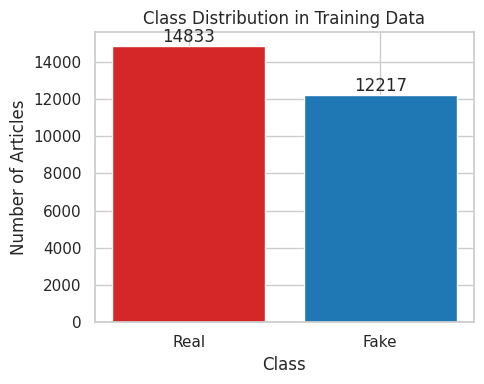

In [7]:
fig, ax = plt.subplots(figsize=(5, 4))
colors = [CLASS_PALETTE[1], CLASS_PALETTE[0]]
ax.bar(class_counts.index, class_counts.values, color=colors)
ax.set_title("Class Distribution in Training Data")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Articles")
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 200, str(v), ha="center")
plt.tight_layout()
plt.show()

## 4. Missing-value analysis

Checked on the training set only. Does not modify the dataset.

In [8]:
print("Missing values (NaN) per column:")
print(train.isnull().sum())
print()
print("Empty (whitespace-only) values per text-bearing column:")
for col in ["title", "text", "clean_text"]:
    empty_count = (train[col].fillna("").astype(str).str.strip() == "").sum()
    print(f"  {col:12s}: {empty_count}")

Missing values (NaN) per column:
title         0
text          0
subject       0
date          0
label         0
article_id    0
clean_text    0
dtype: int64

Empty (whitespace-only) values per text-bearing column:
  title       : 0


  text        : 0
  clean_text  : 0


All Phase 2 cleaning steps already removed empty/missing text and missing titles before this data was
saved, so we expect (and confirm above) zero missing/empty values here. This cell exists to *verify* that
expectation on the actual saved file, not to redo any cleaning.

## 5. Article length analysis

We compute character count, word count, and an approximate sentence count **for EDA purposes only** — these
are temporary Series used for plotting/analysis in this notebook, not new columns saved back to any CSV.

In [9]:
def count_sentences(text):
    """Rough sentence count: count sequences of '.', '!', or '?' as sentence boundaries.
    This is an approximation (news text has abbreviations, quotes, etc.) - good enough for
    a comparative EDA statistic, not intended as a precise linguistic sentence splitter."""
    if not isinstance(text, str) or not text.strip():
        return 0
    return len(re.findall(r'[.!?]+', text))

train["_char_count"] = train["clean_text"].str.len()
train["_word_count"] = train["clean_text"].str.split().apply(len)
train["_sentence_count"] = train["clean_text"].apply(count_sentences)

print("Word count - overall:")
print(train["_word_count"].describe())

Word count - overall:
count    27050.000000
mean       402.044584
std        308.725556
min          1.000000
25%        215.000000
50%        368.000000
75%        510.000000
max       7928.000000
Name: _word_count, dtype: float64


In [10]:
print("Word count - Fake vs Real:")
print(train.groupby("label")["_word_count"].describe().rename(index=LABEL_NAMES))

Word count - Fake vs Real:
         count        mean         std   min    25%    50%    75%     max
label                                                                    
Real   14833.0  384.143936  271.267066  23.0  149.0  357.0  522.0  3690.0
Fake   12217.0  423.778260  347.614580   1.0  276.0  375.0  502.0  7928.0


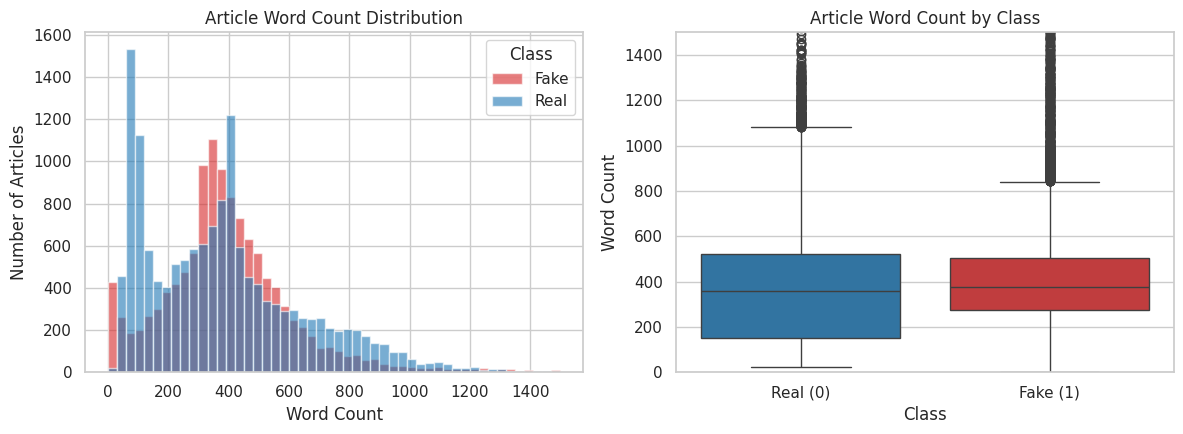

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for label, name in LABEL_NAMES.items():
    subset = train.loc[train["label"] == label, "_word_count"]
    axes[0].hist(subset, bins=50, range=(0, 1500), alpha=0.6, label=name, color=CLASS_PALETTE[label])
axes[0].set_title("Article Word Count Distribution")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Number of Articles")
axes[0].legend(title="Class")

sns.boxplot(
    data=train, x="label", y="_word_count", ax=axes[1],
    palette=CLASS_PALETTE, hue="label", legend=False,
)
axes[1].set_ylim(0, 1500)
axes[1].set_title("Article Word Count by Class")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Word Count")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Real (0)", "Fake (1)"])

plt.tight_layout()
plt.show()

**Observation:** in this training set, fake articles have a slightly higher mean word count than real
articles, but real articles show a tighter, more consistent length distribution (smaller standard
deviation). Both distributions overlap substantially — article length alone does not cleanly separate the
two classes. This should not be read as "longer articles are more likely fake".

## 6. Title analysis

Title character/word length, and whether fake titles show more "sensational" surface characteristics
(uppercase words, exclamation marks, question marks) — all checked directly against the data, not assumed.

In [12]:
train["_title_char_count"] = train["title"].fillna("").astype(str).str.len()
train["_title_word_count"] = train["title"].fillna("").astype(str).str.split().apply(len)

print("Title word count - Fake vs Real:")
print(train.groupby("label")["_title_word_count"].agg(["mean", "median", "std", "min", "max"]).rename(index=LABEL_NAMES))

Title word count - Fake vs Real:
            mean  median       std  min  max
label                                       
Real    9.953347    10.0  1.706635    4   20
Fake   14.352951    14.0  3.960286    1   42


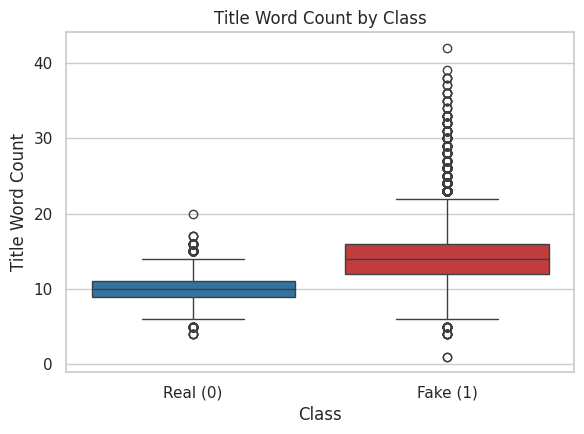

In [13]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=train, x="label", y="_title_word_count", palette=CLASS_PALETTE, hue="label", legend=False, ax=ax)
ax.set_title("Title Word Count by Class")
ax.set_xlabel("Class")
ax.set_ylabel("Title Word Count")
ax.set_xticks([0, 1])
ax.set_xticklabels(["Real (0)", "Fake (1)"])
plt.tight_layout()
plt.show()

In [14]:
def uppercase_letter_ratio(s):
    """Share of alphabetic characters in the string that are uppercase. 0.0 for no letters."""
    letters = [c for c in s if c.isalpha()]
    if not letters:
        return 0.0
    return sum(1 for c in letters if c.isupper()) / len(letters)

train["_title_upper_ratio"] = train["title"].fillna("").astype(str).apply(uppercase_letter_ratio)
train["_title_exclamations"] = train["title"].fillna("").astype(str).str.count("!")
train["_title_questions"] = train["title"].fillna("").astype(str).str.count(r"\?")

title_style = train.groupby("label")[["_title_upper_ratio", "_title_exclamations", "_title_questions"]].mean()
title_style.index = title_style.index.map(LABEL_NAMES)
title_style.columns = ["Mean Uppercase-Letter Ratio", "Mean '!' per Title", "Mean '?' per Title"]
title_style.round(4)

,Mean Uppercase-Letter Ratio,Mean '!' per Title,Mean '?' per Title
label,,,
Real,0.0667,0.0011,0.0067
Fake,0.3478,0.1223,0.0602


In [15]:
pct_with_excl = train.groupby("label")["_title_exclamations"].apply(lambda s: (s > 0).mean() * 100).rename(index=LABEL_NAMES)
print("Percent of titles containing at least one '!':")
print(pct_with_excl.round(2))

Percent of titles containing at least one '!':
label
Real     0.11
Fake    11.01
Name: _title_exclamations, dtype: float64


**Observations actually supported by this data:**
- Fake titles in this training set average noticeably *more* words than real titles.
- Fake titles have a substantially higher uppercase-letter ratio than real titles — real (Reuters-style)
  titles are close to standard sentence case, while a meaningful share of fake titles use partial or full
  capitalization (a common clickbait/tabloid convention).
- Exclamation marks are rare overall, but appear in roughly a tenth of fake titles versus almost none of
  the real titles.
- Question marks in titles are rare in both classes, slightly more common in fake titles.

These are patterns *in this dataset*, and plausibly reflect real editorial style differences between the
sources ISOT collected fake vs. real articles from — not a guarantee that any given uppercase or
exclamation-heavy headline is fake.

## 7. Subject/category analysis

**`subject` is not used as a model feature anywhere in this project** (see Phase 2 and 4 documentation) —
this section exists purely to understand the dataset, because what we find here matters a lot for how we
interpret *every other* result in this notebook.

In [16]:
print(f"Number of unique subjects: {train['subject'].nunique()}")
print()
print("Subject frequency (overall):")
print(train["subject"].value_counts())

Number of unique subjects: 8

Subject frequency (overall):
subject
politicsNews       7796
worldnews          7037
News               6330
politics           3057
left-news          1688
Government News     607
Middle-east         274
US_News             261
Name: count, dtype: int64


In [17]:
subject_by_class = pd.crosstab(train["subject"], train["label"]).rename(columns=LABEL_NAMES)
subject_by_class

label,Real,Fake
subject,,
Government News,0,607
Middle-east,0,274
News,0,6330
US_News,0,261
left-news,0,1688
politics,0,3057
politicsNews,7796,0
worldnews,7037,0


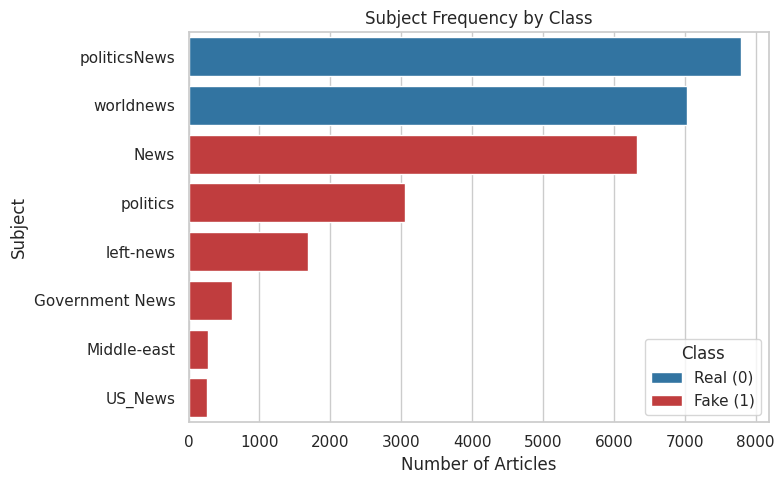

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
subject_order = train["subject"].value_counts().index
sns.countplot(
    data=train, y="subject", hue="label", order=subject_order,
    palette=CLASS_PALETTE, ax=ax,
)
ax.set_title("Subject Frequency by Class")
ax.set_xlabel("Number of Articles")
ax.set_ylabel("Subject")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Real (0)", "Fake (1)"], title="Class")
plt.tight_layout()
plt.show()

**Important dataset artifact:** the crosstab above shows the subject categories used for fake and real
articles **do not overlap at all**. Real articles only ever carry `politicsNews` or `worldnews`; fake
articles only ever carry `News`, `politics`, `Government News`, `left-news`, `US_News`, or `Middle-east`.

This means `subject` alone would let a trivial model achieve perfect separation on this dataset — which
tells us nothing about detecting fake news in general, only that ISOT's fake and real articles were sourced
from different outlets/collections with non-overlapping category taxonomies. This is exactly why `subject`
must **not** be used as a model feature (Phase 2 and this notebook both exclude it), and why any Phase 4
model's real-world generalization should be treated cautiously — the model must learn from article
*content*, not from a proxy that only exists because of how this dataset happens to be organized.

## 8. Date analysis

The `date` column uses inconsistent formats (full vs. abbreviated month names, inconsistent trailing
whitespace) and, in rare cases, garbage values. We parse what we can, and explicitly report what we can't —
we never force an invalid value into a fabricated date. **`date` is not used as a model feature.**

In [19]:
dates_stripped = train["date"].astype(str).str.strip()
parsed_dates = pd.to_datetime(dates_stripped, format="mixed", errors="coerce")

num_parsed = parsed_dates.notna().sum()
num_unparsed = parsed_dates.isna().sum()

print(f"Successfully parsed : {num_parsed} / {len(train)} ({num_parsed / len(train):.2%})")
print(f"Could not parse      : {num_unparsed}")
if num_unparsed > 0:
    print()
    print("Unparseable raw values:")
    for v in train.loc[parsed_dates.isna(), "date"].tolist():
        print(" ", repr(v))

Successfully parsed : 27048 / 27050 (99.99%)
Could not parse      : 2

Unparseable raw values:
  'https://100percentfedup.com/served-roy-moore-vietnamletter-veteran-sets-record-straight-honorable-decent-respectable-patriotic-commander-soldier/'
  'https://fedup.wpengine.com/wp-content/uploads/2015/04/hillarystreetart.jpg'


The unparseable values above are not malformed dates at all — they are **URLs that ended up in the `date`
column**, a data-entry/scraping artifact in the original ISOT source files. This is reported as a known
dataset limitation, not corrected or guessed at.

In [20]:
train_with_dates = train.copy()
train_with_dates["_parsed_date"] = parsed_dates

for label, name in LABEL_NAMES.items():
    subset = train_with_dates.loc[train_with_dates["label"] == label, "_parsed_date"].dropna()
    print(f"{name} date range: {subset.min().date()} to {subset.max().date()}  (n={len(subset)})")

Fake date range: 2015-03-31 to 2018-02-19  (n=12215)
Real date range: 2016-01-13 to 2017-12-31  (n=14833)


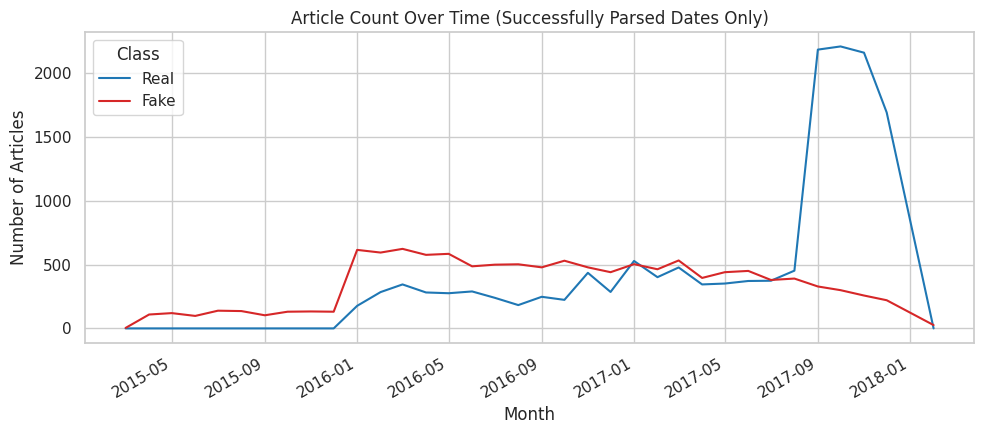

In [21]:
monthly_counts = (
    train_with_dates.dropna(subset=["_parsed_date"])
    .assign(_month=lambda d: d["_parsed_date"].dt.to_period("M").dt.to_timestamp())
    .groupby(["_month", "label"])
    .size()
    .unstack(fill_value=0)
    .rename(columns=LABEL_NAMES)
)

fig, ax = plt.subplots(figsize=(10, 4.5))
monthly_counts.plot(ax=ax, color=[CLASS_PALETTE[0], CLASS_PALETTE[1]])
ax.set_title("Article Count Over Time (Successfully Parsed Dates Only)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Articles")
ax.legend(title="Class")
plt.tight_layout()
plt.show()

**Observation:** real articles' dates fall inside a narrower window than fake articles' dates (fake
articles span a noticeably wider date range). This is consistent with the two classes being collected from
different sources over different collection periods — another dataset-collection artifact worth keeping in
mind, and a further reason `date` should never be used as a model feature (it could otherwise act as a
disguised proxy for source/label, the same concern as `subject` above).

## 9. Word frequency analysis

Using `clean_text` (already stripped of HTML/whitespace noise, case and punctuation preserved) for word
frequency. Common English stopwords are removed **only for this frequency analysis** — the underlying
`clean_text` column itself is never modified.

We use bar charts as the primary visualization (word clouds are decorative and don't add analytical rigor
beyond what a frequency bar chart already shows, so this project skips them, per the "avoid decorative
visualizations" guidance).

In [22]:
# CountVectorizer with English stopword removal - much faster and more memory-efficient
# than a manual Python loop over ~27k documents.
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=20000,
    lowercase=True,
    token_pattern=r"[A-Za-z]{2,}",  # words of 2+ alphabetic characters only
)
word_matrix = vectorizer.fit_transform(train["clean_text"])
vocabulary = np.array(vectorizer.get_feature_names_out())

overall_freqs = np.asarray(word_matrix.sum(axis=0)).ravel()
fake_mask = (train["label"] == 1).values
real_mask = (train["label"] == 0).values

fake_freqs = np.asarray(word_matrix[fake_mask].sum(axis=0)).ravel()
real_freqs = np.asarray(word_matrix[real_mask].sum(axis=0)).ravel()

print(f"Vocabulary size (after stopword removal, top {word_matrix.shape[1]} features): {word_matrix.shape[1]}")

Vocabulary size (after stopword removal, top 20000 features): 20000


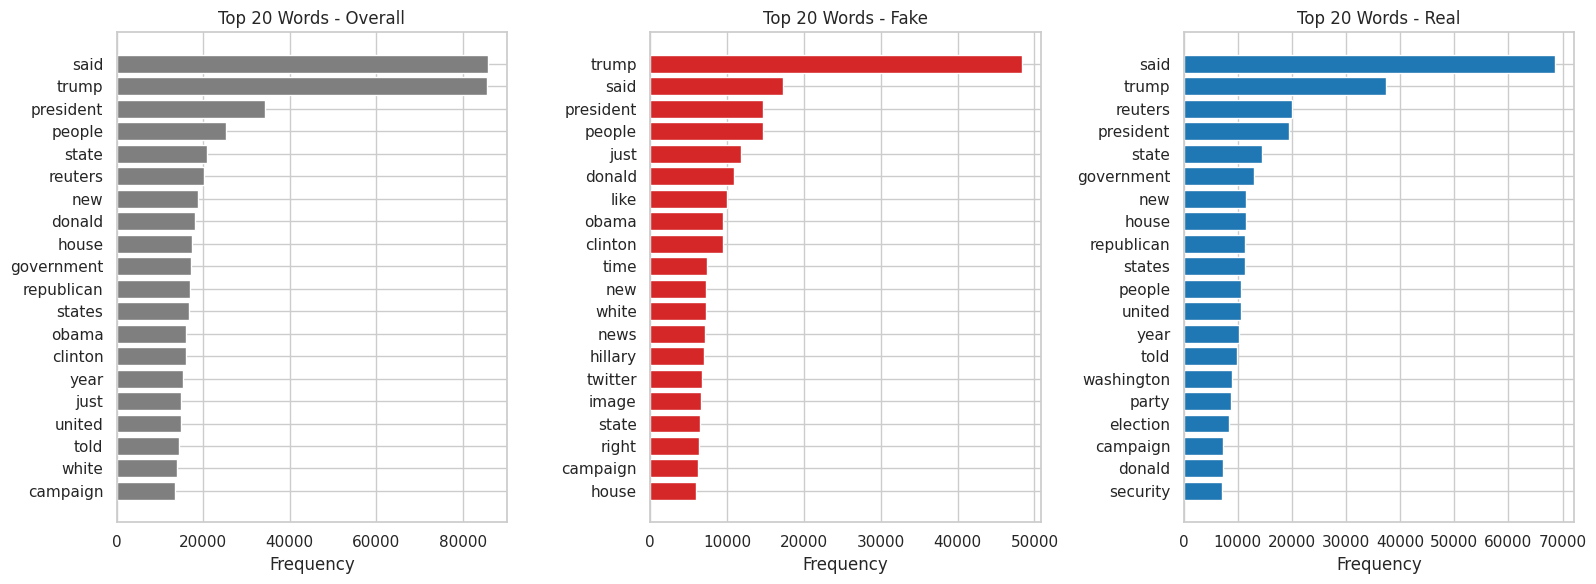

In [23]:
def top_n_words(vocab, freqs, n=20):
    top_idx = np.argsort(-freqs)[:n]
    return pd.DataFrame({"word": vocab[top_idx], "count": freqs[top_idx]})

top_overall = top_n_words(vocabulary, overall_freqs, 20)
top_fake = top_n_words(vocabulary, fake_freqs, 20)
top_real = top_n_words(vocabulary, real_freqs, 20)

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharex=False)

for ax, df, title, color in [
    (axes[0], top_overall, "Top 20 Words - Overall", "#7f7f7f"),
    (axes[1], top_fake, "Top 20 Words - Fake", CLASS_PALETTE[1]),
    (axes[2], top_real, "Top 20 Words - Real", CLASS_PALETTE[0]),
]:
    ax.barh(df["word"][::-1], df["count"][::-1], color=color)
    ax.set_title(title)
    ax.set_xlabel("Frequency")

plt.tight_layout()
plt.show()

## 10. Class-specific word analysis

Which words appear *disproportionately* often in one class relative to the other? Raw frequency isn't
enough here (a word can be common in both classes) — we use a **log-frequency ratio** of each word's rate
within fake articles vs. its rate within real articles, restricted to words that appear at least 50 times
overall so we're not chasing noise from rare words.

This is exploratory only — no classifier is trained here, and this analysis uses only the training set.

In [24]:
MIN_TOTAL_COUNT = 50
total_freqs = fake_freqs + real_freqs
frequent_enough = total_freqs >= MIN_TOTAL_COUNT

fake_rate = fake_freqs / fake_mask.sum()   # rate per fake document
real_rate = real_freqs / real_mask.sum()   # rate per real document

epsilon = 1e-6  # smoothing to avoid division by zero / log(0)
log_ratio = np.log((fake_rate + epsilon) / (real_rate + epsilon))

eligible_idx = np.where(frequent_enough)[0]
fake_biased_idx = eligible_idx[np.argsort(-log_ratio[eligible_idx])][:15]
real_biased_idx = eligible_idx[np.argsort(log_ratio[eligible_idx])][:15]

fake_biased_df = pd.DataFrame({
    "word": vocabulary[fake_biased_idx],
    "log_ratio": log_ratio[fake_biased_idx].round(2),
    "fake_count": fake_freqs[fake_biased_idx].astype(int),
    "real_count": real_freqs[fake_biased_idx].astype(int),
})
real_biased_df = pd.DataFrame({
    "word": vocabulary[real_biased_idx],
    "log_ratio": log_ratio[real_biased_idx].round(2),
    "fake_count": fake_freqs[real_biased_idx].astype(int),
    "real_count": real_freqs[real_biased_idx].astype(int),
})

print("Words most disproportionately common in FAKE articles (min. 50 total occurrences):")
display(fake_biased_df)

Words most disproportionately common in FAKE articles (min. 50 total occurrences):


,word,log_ratio,fake_count,real_count
0,https,12.24,2540,0
1,flickr,10.46,426,0
2,somodevilla,10.23,337,0
3,boiler,10.16,317,0
4,acr,10.03,276,0
5,filessupport,9.73,205,0
6,mcnamee,9.66,192,0
7,angerer,9.60,180,0
8,youtu,9.57,175,0
9,finicum,9.53,168,0


In [25]:
print("Words most disproportionately common in REAL articles (min. 50 total occurrences):")
display(real_biased_df)

Words most disproportionately common in REAL articles (min. 50 total occurrences):


,word,log_ratio,fake_count,real_count
0,hariri,-10.69,0,649
1,rakhine,-10.64,0,620
2,puigdemont,-10.35,0,463
3,zuma,-10.31,0,446
4,kyi,-10.10,0,362
5,suu,-10.10,0,361
6,mnangagwa,-9.79,0,265
7,odinga,-9.76,0,256
8,anc,-9.76,0,256
9,krg,-9.68,0,237


**This is one of the most important findings in this notebook, and it is a caution, not a celebration.**

The words most strongly associated with the "fake" class are **not** emotionally charged or sensational
language — they are things like `https`, `flickr`, `wikimedia`, `youtu`, and surnames of Getty Images
photographers (e.g. `somodevilla`, `mcnamee`, `angerer`). These are **embedded image-credit and URL
metadata** that ended up inside the article body text during scraping — an artifact of *how this dataset was
collected*, not a linguistic property of misinformation.

Symmetrically, the words most associated with "real" articles are mostly **foreign political figures' names
and places** (`hariri`, `rakhine`, `puigdemont`, `zuma`, `kyi`/`suu`, `mnangagwa`, `rajoy`, `kurz`) plus
`tmsnrt` — which is literally a fragment of Reuters' internal graphics short-link domain
(`tmsnrt.rs/...`), another **publisher-specific artifact**, not a topic or style signal.

**Implication for Phase 4:** a classifier trained on raw `clean_text` may partly learn to detect *which
source scraped/collected the article* (via leftover URLs, photo-credit names, or agency-specific link
domains) rather than learning general characteristics of misinformation. This is a known limitation of the
ISOT dataset discussed in the wider fake-news-detection literature, and is called out explicitly here rather
than hidden — see Section 17 (Key Findings) and Section 18 (Potential Features for Phase 4) for how this
should inform feature choices later.

## 11. Linguistic analysis

A concise comparison of style-related characteristics between fake and real articles, computed directly on
`clean_text` (case and punctuation are preserved in `clean_text`, so these signals are still measurable).

In [26]:
def uppercase_word_ratio(text):
    """Share of whitespace-separated tokens that are fully uppercase and at least 2 letters long
    (avoids counting single-letter tokens like 'A' or 'I')."""
    if not isinstance(text, str) or not text.strip():
        return 0.0
    words = text.split()
    alpha_words = [w for w in words if any(c.isalpha() for c in w)]
    if not alpha_words:
        return 0.0
    upper_words = [w for w in alpha_words if w.isupper() and len(w) >= 2]
    return len(upper_words) / len(alpha_words)

train["_text_exclamations"] = train["clean_text"].str.count("!")
train["_text_questions"] = train["clean_text"].str.count(r"\?")
train["_text_upper_word_ratio"] = train["clean_text"].apply(uppercase_word_ratio)
train["_avg_sentence_len_words"] = train["_word_count"] / train["_sentence_count"].replace(0, np.nan)

linguistic_cols = {
    "_word_count": "Mean Word Count",
    "_sentence_count": "Mean Sentence Count (approx.)",
    "_avg_sentence_len_words": "Mean Words per Sentence",
    "_text_exclamations": "Mean '!' per Article",
    "_text_questions": "Mean '?' per Article",
    "_text_upper_word_ratio": "Mean Fully-Uppercase Word Ratio",
}

linguistic_summary = train.groupby("label")[list(linguistic_cols.keys())].mean()
linguistic_summary.index = linguistic_summary.index.map(LABEL_NAMES)
linguistic_summary.columns = list(linguistic_cols.values())
linguistic_summary.round(3)

,Mean Word Count,Mean Sentence Count (approx.),Mean Words per Sentence,Mean '!' per Article,Mean '?' per Article,Mean Fully-Uppercase Word Ratio
label,,,,,,
Real,384.144,20.723,19.942,0.063,0.095,0.019
Fake,423.778,22.988,19.335,0.729,1.231,0.019


**Observations:** fake articles in this training set show, on average, more exclamation marks and a higher
share of fully-uppercase words in the article body than real articles — consistent with the title-level
pattern found in Section 6. Sentence counts and words-per-sentence are broadly similar between classes,
suggesting overall writing structure (not just punctuation/capitalization style) is less distinctive between
the two classes than headline style is.

## 12. Outlier analysis

Identifying unusually short/long articles and titles using the IQR (interquartile range) method — a
standard, distribution-agnostic way to flag statistical outliers. **Nothing is removed here** — Phase 2
already handled required data-quality filtering; this section only reports.

In [27]:
def iqr_bounds(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col, label in [("_word_count", "Article word count"), ("_title_word_count", "Title word count")]:
    lower, upper = iqr_bounds(train[col])
    below = (train[col] < lower).sum()
    above = (train[col] > upper).sum()
    print(f"{label}: IQR bounds = [{max(lower, 0):.0f}, {upper:.0f}]")
    print(f"  Below lower bound: {below} articles ({below / len(train):.2%})")
    print(f"  Above upper bound: {above} articles ({above / len(train):.2%})")
    print()

Article word count: IQR bounds = [0, 952]
  Below lower bound: 0 articles (0.00%)
  Above upper bound: 953 articles (3.52%)

Title word count: IQR bounds = [2, 22]
  Below lower bound: 2 articles (0.01%)
  Above upper bound: 667 articles (2.47%)



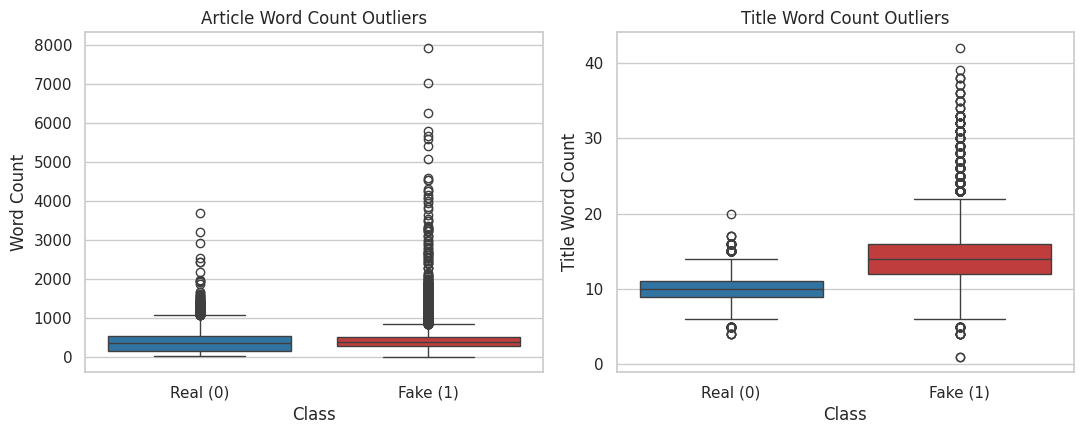

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.boxplot(data=train, x="label", y="_word_count", palette=CLASS_PALETTE, hue="label", legend=False, ax=axes[0])
axes[0].set_title("Article Word Count Outliers")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Word Count")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Real (0)", "Fake (1)"])

sns.boxplot(data=train, x="label", y="_title_word_count", palette=CLASS_PALETTE, hue="label", legend=False, ax=axes[1])
axes[1].set_title("Title Word Count Outliers")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Title Word Count")
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Real (0)", "Fake (1)"])

plt.tight_layout()
plt.show()

**Observation:** article length has a meaningful number of upper-bound outliers (very long articles) in
both classes, while almost no lower-bound outliers remain — expected, since Phase 2 already removed
empty/near-empty articles. These long-tail articles are kept as-is; Phase 4 can decide whether length
capping/truncation is needed for specific modeling approaches (e.g. transformer input length limits).

## 13. Duplicate / overlap diagnostics

This section re-checks the Phase 2 leakage guarantees directly on the saved processed files, as an
independent diagnostic. **Validation and test sets are loaded here only for this overlap check** — never
for pattern exploration or feature/model decisions. Nothing is modified.

In [29]:
# --- Within-train duplicates ---
raw_text_dupes_in_train = train["text"].duplicated().sum()
clean_text_dupes_in_train = train["clean_text"].duplicated().sum()

print("=== Within-training-set duplicates ===")
print(f"Duplicate raw 'text' values in train   : {raw_text_dupes_in_train}")
print(f"Duplicate 'clean_text' values in train : {clean_text_dupes_in_train}")

=== Within-training-set duplicates ===
Duplicate raw 'text' values in train   : 0
Duplicate 'clean_text' values in train : 3


In [30]:
if clean_text_dupes_in_train > 0:
    dup_mask = train["clean_text"].duplicated(keep=False)
    print(f"\n{dup_mask.sum()} rows involved in within-train clean_text duplicates. Example groups:")
    shown = 0
    for ct, group in train[dup_mask].groupby("clean_text"):
        if shown >= 3:
            break
        print(f"\n  Group of {len(group)} rows, sample titles:")
        for t in group["title"].tolist():
            print(f"    - {t[:80]}")
        shown += 1


6 rows involved in within-train clean_text duplicates. Example groups:

  Group of 2 rows, sample titles:
    - TWITTER Posts Hilarious Images After Announcement That It’s NOW ILLEGAL To Post 
    - TWITTER USERS Post Hilarious Responses To Russia’s Ban On Gay Images Of Putin

  Group of 2 rows, sample titles:
    - Factbox: Trump on Twitter (Sept 18) - U.S. Air Force, CIA
    - Factbox: Trump on Twitter (Sept 18) - U.S. Air Force, CIA

  Group of 2 rows, sample titles:
    - ARROGANT ILLEGAL ALIEN Who Voted 5 Times In 2016 Election Gets 8 Years…Lawyers C
    - TRUMP’S BRILLIANT Director Of Communications OMAROSA Absolutely DESTROYS Joy Beh


**Explanation:** Phase 2 removes exact-match `text` duplicates before saving these files (confirmed above:
0 duplicate raw text within train). The `clean_text` duplicates found here have **different** raw `text`
(so they correctly survived Phase 2's exact-match deduplication) but become identical after light cleaning —
typically because the only difference was trailing/internal whitespace. This is the same known, narrow edge
case documented in the Phase 2 README section (affecting a handful of rows out of tens of thousands), and is
reported here again as a diagnostic, not corrected — Phase 2 already made a documented, deliberate choice
not to merge these via aggressive normalization, because doing so was shown to risk deleting genuinely
different short articles that happen to share boilerplate text.

In [31]:
# --- Cross-split overlap (diagnostic use of val/test only) ---
train_ids, val_ids, test_ids = set(train["article_id"]), set(val["article_id"]), set(test["article_id"])
train_text, val_text, test_text = set(train["text"]), set(val["text"]), set(test["text"])
train_clean, val_clean, test_clean = set(train["clean_text"]), set(val["clean_text"]), set(test["clean_text"])

def overlap_report(a, b, name_a, name_b, what):
    n = len(a & b)
    print(f"  {name_a} vs {name_b} ({what}): {n}")

print("=== article_id overlap across splits (should always be 0) ===")
overlap_report(train_ids, val_ids, "train", "val", "article_id")
overlap_report(train_ids, test_ids, "train", "test", "article_id")
overlap_report(val_ids, test_ids, "val", "test", "article_id")

print("\n=== raw text overlap across splits (should always be 0) ===")
overlap_report(train_text, val_text, "train", "val", "text")
overlap_report(train_text, test_text, "train", "test", "text")
overlap_report(val_text, test_text, "val", "test", "text")

print("\n=== clean_text overlap across splits (reported, not a hard failure - see Phase 2 README) ===")
overlap_report(train_clean, val_clean, "train", "val", "clean_text")
overlap_report(train_clean, test_clean, "train", "test", "clean_text")
overlap_report(val_clean, test_clean, "val", "test", "clean_text")

=== article_id overlap across splits (should always be 0) ===
  train vs val (article_id): 0
  train vs test (article_id): 0
  val vs test (article_id): 0

=== raw text overlap across splits (should always be 0) ===
  train vs val (text): 0
  train vs test (text): 0
  val vs test (text): 0

=== clean_text overlap across splits (reported, not a hard failure - see Phase 2 README) ===
  train vs val (clean_text): 3
  train vs test (clean_text): 0
  val vs test (clean_text): 0


**Confirms the Phase 2 guarantees directly on the saved files:** zero `article_id` overlap and zero raw
`text` overlap between any pair of splits (the hard leakage guarantees both hold). A small `clean_text`
overlap between train and validation is expected and already documented in Phase 2 — it does not indicate
new leakage, just the same trailing-whitespace edge case seen above, now visible across split boundaries
too.

## 14. Key EDA Findings

All findings below are specific to **this training set** (27,050 articles from the ISOT dataset after Phase
2 cleaning), not universal claims about fake news.

In [32]:
print("Summary numbers referenced in the findings below:")
print(f"  Training set size           : {len(train)}")
print(f"  Fake / Real                 : {(train['label']==1).sum()} / {(train['label']==0).sum()}"
      f"  ({(train['label']==1).mean():.1%} / {(train['label']==0).mean():.1%})")
print(f"  Mean word count (fake/real) : {train.loc[train.label==1,'_word_count'].mean():.0f} / "
      f"{train.loc[train.label==0,'_word_count'].mean():.0f}")
print(f"  Mean title words (fake/real): {train.loc[train.label==1,'_title_word_count'].mean():.1f} / "
      f"{train.loc[train.label==0,'_title_word_count'].mean():.1f}")
print(f"  Mean title upper ratio (fake/real): {train.loc[train.label==1,'_title_upper_ratio'].mean():.2f} / "
      f"{train.loc[train.label==0,'_title_upper_ratio'].mean():.2f}")
print(f"  Unique subjects             : {train['subject'].nunique()} (zero overlap between classes)")
print(f"  Dates successfully parsed   : {num_parsed} / {len(train)} ({num_parsed/len(train):.1%})")

Summary numbers referenced in the findings below:
  Training set size           : 27050
  Fake / Real                 : 12217 / 14833  (45.2% / 54.8%)
  Mean word count (fake/real) : 424 / 384
  Mean title words (fake/real): 14.4 / 10.0
  Mean title upper ratio (fake/real): 0.35 / 0.07
  Unique subjects             : 8 (zero overlap between classes)
  Dates successfully parsed   : 27048 / 27050 (100.0%)


1. **Class balance:** the training set is moderately imbalanced — 45.2% fake vs. 54.8% real. Not severe,
   but worth accounting for in Phase 4 (e.g. via stratification, already done in Phase 2, and by checking
   metrics beyond raw accuracy such as F1 and per-class recall).
2. **Article length:** fake articles have a slightly higher mean word count than real articles, but the
   distributions overlap heavily — length alone is a weak signal for this task.
3. **Title length:** fake titles average about 14 words vs. about 10 for real titles — a more distinct
   difference than body length.
4. **Title capitalization:** fake titles have a much higher uppercase-letter ratio (~35%) than real titles
   (~7%) — consistent with tabloid/clickbait-style headline conventions in the fake-article sources.
5. **Title punctuation:** exclamation marks appear in about 11% of fake titles versus roughly 0.1% of real
   titles — a large relative difference, though exclamation marks are rare overall in both classes.
6. **Subject is a near-perfect (in fact, exact) separator** between fake and real articles in this dataset —
   the two classes use completely non-overlapping subject taxonomies. This is a strong sign of a
   dataset-collection artifact (different sources/scrapes), not a property of "fakeness" itself, and is why
   `subject` is explicitly excluded as a model feature.
7. **Date coverage** parses successfully for 27,048 of 27,050 articles (99.99%); the 2 failures are URLs
   that were mistakenly placed in the `date` field in the original source data, not actual dates.
8. **Date range differs by class**: fake articles' dates span a wider window than real articles' dates,
   suggesting the two classes were collected over different time periods — another potential
   source-identifying artifact, and a further reason `date` is excluded as a feature.
9. **Embedded metadata in article text:** the words most disproportionately common in fake articles are not
   stylistic/emotional language but embedded URL and image-credit artifacts (`https`, `flickr`, `wikimedia`,
   `youtu`, and Getty photographer surnames). Symmetrically, words most common in real articles are largely
   foreign political figures' names plus a Reuters-internal short-link fragment (`tmsnrt`). This is the
   single most important caution in this notebook: **some of what separates "fake" from "real" in this
   dataset is about data provenance, not content quality.**
10. **Duplicate patterns:** Phase 2 already removed all exact-text duplicates and the one genuine cross-class
    label conflict (documented there). A small number of near-duplicate articles (differing only by trivial
    whitespace) remain visible at the `clean_text` level — a narrow, disclosed edge case affecting a handful
    of rows out of tens of thousands, not a correctness issue.
11. **Outliers:** essentially no unusually short articles remain (Phase 2 already filtered those out), but a
    meaningful long tail of unusually long articles exists in both classes — worth considering for any
    model or transformer with an input-length limit in later phases.
12. **Sentence-level structure** (approximate sentence count, words per sentence) is broadly similar between
    classes — the two classes differ more in headline/punctuation style than in overall prose structure.

## 15. Potential Features for Phase 4

Based on everything above, candidate features for the ML baseline (Phase 4) — **none are trained or
finalized here**:

**Likely useful:**
- **TF-IDF on `clean_text`** (word-level, 1-2 grams) — the standard, strong baseline for this kind of task.
- **Character n-grams** — could help catch stylistic/spelling patterns TF-IDF word-level features miss, at
  the cost of a larger feature space.
- **Title-derived features** — title word count, uppercase ratio, exclamation/question-mark counts. Section
  6's findings suggest these carry real signal, and unlike `subject`/`date` they come from article
  *content*, not dataset structure.
- **Article length** (word/character count) — weak on its own (Section 5), but cheap to add alongside
  stronger text features.
- **Punctuation-density features** more broadly (Section 11) — exclamation/question mark rates, uppercase
  word ratio in the body.

**Should probably be avoided, or used only with explicit caution and disclosure:**
- **`subject`** — Section 7 showed this is a near-perfect class separator purely because of how ISOT
  organized its source files, not because it reflects anything about article veracity. Using it would
  produce a model that looks excellent on this dataset and generalizes to nothing.
- **`date`** — Section 8 showed real and fake articles were collected over different, only partially
  overlapping time windows. Using it risks the same problem as `subject`.
- **Raw URLs / image-credit tokens surfaced in Section 10** (`https`, `flickr`, `wikimedia`, `youtu`,
  photographer surnames, `tmsnrt`) — worth considering whether to strip these during Phase 4 feature
  engineering specifically *because* they're dataset artifacts rather than content signal. This is a Phase 4
  decision (documented here so it isn't forgotten), not something Phase 2/3 alters.
- **`article_id`** and any other dataset-internal identifier — by construction these have no relationship to
  the article's actual content and exist purely for this project's leakage-prevention bookkeeping.

## 16. Data-Leakage Reminder

Consistent with Phase 2: **the test set (`test.csv`) was not explored for patterns anywhere in this
notebook.** It was loaded in Section 13 solely to confirm the Phase 2 overlap/leakage guarantees still hold
on the saved files — a diagnostic check, not an analysis used to choose features, tune thresholds, or select
a model. All feature and modeling decisions above are based on `train.csv` only. Validation-set patterns
were likewise not explored (it appeared only in the same diagnostic overlap check); it remains available,
untouched, for model selection in Phase 4.

## 17. Conclusion

This training set (27,050 articles, 45.2% fake / 54.8% real, after Phase 2 cleaning) shows measurable
differences between fake and real articles in **headline style** (length, capitalization, punctuation) and
some difference in **body length**, but the most statistically distinctive signals found — the `subject`
category and specific embedded URL/photo-credit tokens — are very likely **dataset-collection artifacts**
rather than general properties of misinformation. This distinction matters directly for Phase 4: a model
that performs well on this test set by exploiting these artifacts would not be a trustworthy fake-news
detector in the real world, which is precisely why this project's design (per the original project brief)
treats the ML classifier's output as one signal among several — combined with LLM-based analysis and
evidence retrieval in later phases — rather than as a standalone verdict.

**Next step: Phase 4 — Machine Learning Baseline** (`notebooks/03_ml_models.ipynb`), where TF-IDF features
and the traditional ML models (Logistic Regression, Naive Bayes, Random Forest, XGBoost) will be trained on
`train.csv`, tuned using `validation.csv`, and evaluated — with `test.csv` reserved untouched until final
evaluation.